In [2]:
import numpy as np
import pandas as pd

df = pd.read_csv('course_lead_scoring_2026.csv')

In [3]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [4]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [6]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

df[categorical].isna().sum()

df[categorical] = df[categorical].fillna("NA")

In [7]:
df[categorical].isna().sum()

lead_source          0
industry             0
employment_status    0
location             0
dtype: int64

In [8]:
df[numerical] = df[numerical].fillna(0)

df[numerical].isna().sum()

annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
dtype: int64

In [9]:
from sklearn.model_selection import train_test_split


df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

assert len(df_full_train) == len(df_train) + len(df_val)
assert len(df_train) + len(df_val) + len(df_test) == len(df)

In [10]:
numerical

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [11]:
from sklearn.metrics import roc_auc_score

y_true = df_train.converted.values
y_true

aucs = []

for var in numerical:
    auc = roc_auc_score(y_true=y_true, y_score=df_train[var].values)
    aucs.append((var, auc))

aucs



[('annual_income', 0.6081977776250831),
 ('number_of_courses_viewed', 0.7229894623989618),
 ('interaction_count', 0.7649203047563227),
 ('lead_score', 0.7882254810906102)]

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

dicts = df_train[categorical + numerical].to_dict(orient="records")

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(dicts)
y_train = df_train.converted.values

model.fit(X_train, y_train)

dicts_val = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(dicts_val)

auc = roc_auc_score(y_true=df_val.converted.values, y_score=model.predict_proba(X_val)[:,1])

round(auc, 3)



0.732

In [13]:
from sklearn.metrics import confusion_matrix


threshold = np.linspace(start=0, stop=1, num=100)
y_true = df_val.converted.values



tn, fp, fn, tp = confusion_matrix(y_true=y_true, y_pred=(model.predict_proba(X_val)[:,1])>0.5).ravel().tolist()
tn, fp, fn, tp


scores = []

for t in threshold:
    tn, fp, fn, tp = confusion_matrix(y_true=y_true, y_pred=(model.predict_proba(X_val)[:,1])>t).ravel().tolist()

    scores.append((t, tn, fp, fn, tp))

columns = ['threshold', 'tn', 'fp', 'fn', 'tp']

df_scores = pd.DataFrame(scores, columns=columns)
df_scores


,threshold,tn,fp,fn,tp
0,0.000000,0,414,0,586
1,0.010101,0,414,0,586
2,0.020202,0,414,0,586
3,0.030303,0,414,0,586
4,0.040404,0,414,0,586
...,...,...,...,...,...
95,0.959596,414,0,585,1
96,0.969697,414,0,586,0
97,0.979798,414,0,586,0
98,0.989899,414,0,586,0


In [14]:
df_scores['tpr'] = df_scores.tp/(df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp/(df_scores.fp + df_scores.tn)
df_scores['precision'] = df_scores.tp/(df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores['tpr']

df_scores

,threshold,tn,fp,fn,tp,tpr,fpr,precision,recall
0,0.000000,0,414,0,586,1.000000,1.0,0.586,1.000000
1,0.010101,0,414,0,586,1.000000,1.0,0.586,1.000000
2,0.020202,0,414,0,586,1.000000,1.0,0.586,1.000000
3,0.030303,0,414,0,586,1.000000,1.0,0.586,1.000000
4,0.040404,0,414,0,586,1.000000,1.0,0.586,1.000000
...,...,...,...,...,...,...,...,...,...
95,0.959596,414,0,585,1,0.001706,0.0,1.000,0.001706
96,0.969697,414,0,586,0,0.000000,0.0,NaN,0.000000
97,0.979798,414,0,586,0,0.000000,0.0,NaN,0.000000
98,0.989899,414,0,586,0,0.000000,0.0,NaN,0.000000


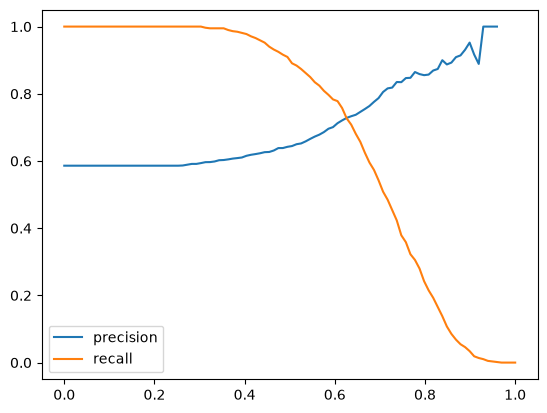

In [15]:
import matplotlib.pyplot as plt

plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.legend()

In [16]:
idx = (df_scores.precision - df_scores.recall).abs().idxmin()
threshold = df_scores.loc[idx, "threshold"]

print(threshold)

0.6262626262626263


In [21]:
df_scores['f1'] = 2*(df_scores.precision * df_scores.recall) /(df_scores.precision + df_scores.recall)

idx = df_scores.f1.idxmax()

df_scores.threshold[42]

np.float64(0.42424242424242425)

In [23]:
from sklearn.model_selection import KFold


kfold = KFold(n_splits=5, shuffle=True, random_state=1)

aucs = []

for train_idx, valid_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_valid = df_full_train.iloc[valid_idx]

    y_train = df_train.converted.values
    y_valid = df_valid.converted.values

    dicts_train = df_train[categorical + numerical].to_dict(orient='records')
    dicts_valid = df_valid[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)

    X_train = dv.fit_transform(dicts_train)
    X_valid = dv.transform(dicts_valid)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    auc = roc_auc_score(y_true=y_valid, y_score=model.predict_proba(X_valid)[:, 1])

    aucs.append(auc)

np.mean(aucs), np.std(aucs)

(np.float64(0.7317269710972524), np.float64(0.006853233151022138))

In [25]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

means = []

for C in [0.000001, 0.001, 1]:
    
    aucs = []

    for train_idx, valid_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_valid = df_full_train.iloc[valid_idx]

        y_train = df_train.converted.values
        y_valid = df_valid.converted.values

        dicts_train = df_train[categorical + numerical].to_dict(orient='records')
        dicts_valid = df_valid[categorical + numerical].to_dict(orient='records')

        dv = DictVectorizer(sparse=False)

        X_train = dv.fit_transform(dicts_train)
        X_valid = dv.transform(dicts_valid)

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train, y_train)

        auc = roc_auc_score(y_true=y_valid, y_score=model.predict_proba(X_valid)[:, 1])

        aucs.append(auc)

    means.append((C, np.mean(aucs)))

means
        

[(1e-06, np.float64(0.6167342250714795)),
 (0.001, np.float64(0.7491721776030379)),
 (1, np.float64(0.7317269710972524))]